# SolarCast Lite: when should a small workshop charge its EV?
**Veritas AI International High School Hackathon 2026 · Track: AI + Climate**

**The user.** The owner of a small workshop with a 50 kW rooftop solar system and an electric vehicle that needs
about 40 kWh every working day. Every hour they face one question: *charge now, or wait for more sun?*

**What we built.** (1) **SolarCast**, a machine-learning model that forecasts the next hour's solar power from recent
power, the sun's position and the weather; (2) a charging rule that uses the forecast to charge when solar power
is left over; (3) a day-by-day replay of four months the model never saw, measuring grid electricity, money and
CO2 saved.

**How to run.** Runtime → **Run all**. Everything (data download, training, evaluation) runs here in about a
minute on a free CPU runtime. Results are a historical replay on held-out data.

*This project is a prototype and is not financial or energy advice.*

In [ ]:
# @title Install the SolarCast package (code hidden; full source: github.com/nashwu0117/SolarCast-Lite)
import sys
from pathlib import Path

PKG_DIR = Path('solarcast_src') / 'src' / 'solarcast'
PKG_DIR.mkdir(parents=True, exist_ok=True)
FILES = {
    '__init__': '"""SolarCast Lite: one-hour-ahead solar PV power forecasting."""\n__version__ = "0.1.0"\n',
    'config': '"""Shared constants. Every module imports from here; do not hard-code these elsewhere."""\nfrom pathlib import Path\n\nREPO_ROOT = Path(__file__).resolve().parents[2]\nDATA_DIR = REPO_ROOT / "data" / "raw"          # downloaded CSVs are cached here (gitignored)\nMODELS_DIR = REPO_ROOT / "models"              # saved models (gitignored)\n\n# Dataset: Two-Site Solar PV Inverter & Weather Dataset (Romania), CC BY 4.0\n# https://github.com/upb-nlp/PV-Generation-Dataset\nDATASET_BASE_URL = "https://raw.githubusercontent.com/upb-nlp/PV-Generation-Dataset/main"\nSITES = {\n    "A": {"csv": "site_a/site_a_hourly_weather.csv", "capacity_kw": 50.0},\n    "B": {"csv": "site_b/site_b_hourly_weather.csv", "capacity_kw": 50.0},\n}\nCAPACITY_KW = 50.0\nLOCAL_TZ = "Europe/Bucharest"\n\n# Columns kept by data.load_site (all others in the CSV are dropped).\nTARGET_COL = "active_power_kw"\nWEATHER_COLS = [\n    "temp_c", "humidity_pct", "cloud_cover_pct", "wind_speed_kmh",\n    "precip_mm", "ghi_wm2", "dni_wm2", "dhi_wm2",\n]\nSOLAR_COLS = ["solar_elevation_deg", "solar_azimuth_deg"]\nKEEP_COLS = [TARGET_COL, "capacity_factor", "is_generating"] + WEATHER_COLS + SOLAR_COLS\n\n# Main evaluation is daytime only: target-hour sun elevation above this (dataset convention).\nDAYTIME_ELEVATION_MIN = 5.0\n\n# Time-based splits on the TARGET hour (UTC), half-open [start, end). Never shuffle.\nSPLITS = {\n    "train": ("2025-01-01", "2026-01-01"),\n    "val":   ("2026-01-01", "2026-03-01"),\n    "test":  ("2026-03-01", "2026-07-01"),\n}\n\n# Sky-condition groups for error analysis, by target-hour cloud cover (%), [low, high).\nSKY_BINS = {"clear": (0, 30), "partly_cloudy": (30, 70), "overcast": (70, 101)}\n\nRANDOM_STATE = 42\n',
    'data': '"""Download and load the hourly solar + weather CSVs into one clean, complete hourly table."""\nimport urllib.request\nfrom pathlib import Path\n\nimport pandas as pd\n\nfrom solarcast import config\n\n\ndef download_site_csv(site: str, force: bool = False) -> Path:\n    """Download a site\'s CSV into config.DATA_DIR (skipped if already cached)."""\n    rel_path = config.SITES[site]["csv"]\n    dest = Path(config.DATA_DIR) / Path(rel_path).name\n    if dest.exists() and not force:\n        return dest\n    dest.parent.mkdir(parents=True, exist_ok=True)\n    url = f"{config.DATASET_BASE_URL}/{rel_path}"\n    with urllib.request.urlopen(url, timeout=60) as response:\n        dest.write_bytes(response.read())\n    return dest\n\n\ndef load_site(site: str) -> pd.DataFrame:\n    """Load a site as a clean table: UTC hourly index, sorted, unique, no missing hours.\n\n    Missing measurements stay NaN (never filled with 0); night zeros are real zeros.\n    """\n    raw = pd.read_csv(download_site_csv(site))\n    raw.index = pd.DatetimeIndex(pd.to_datetime(raw["datetime_utc"]), name="datetime_utc").tz_localize("UTC")\n    raw = raw.sort_index()\n\n    n_duplicates = int(raw.index.duplicated().sum())\n    raw = raw[~raw.index.duplicated(keep="first")]\n\n    full_grid = pd.date_range(raw.index[0], raw.index[-1], freq="h", tz="UTC", name="datetime_utc")\n    df = raw[config.KEEP_COLS].astype(float).reindex(full_grid)  # missing hours become NaN rows\n\n    df.attrs["n_duplicate_timestamps_in_csv"] = n_duplicates\n    df.attrs["n_inserted_gap_rows"] = len(full_grid) - len(raw)\n    return df\n\n\ndef data_quality_report(df: pd.DataFrame) -> dict:\n    """Summarise size, date range, missing values and daytime share of a load_site table."""\n    daytime = df["solar_elevation_deg"] > config.DAYTIME_ELEVATION_MIN\n    return {\n        "n_rows": len(df),\n        "start": df.index[0],\n        "end": df.index[-1],\n        "n_missing_power": int(df[config.TARGET_COL].isna().sum()),\n        "n_missing_weather": int(df[config.WEATHER_COLS].isna().any(axis=1).sum()),\n        "n_duplicate_timestamps_in_csv": df.attrs.get("n_duplicate_timestamps_in_csv", 0),\n        "n_inserted_gap_rows": df.attrs.get("n_inserted_gap_rows", 0),\n        "pct_daytime": round(100 * float(daytime.mean()), 1),\n    }\n',
    'features': '"""Turn a load_site table into one row per target hour: features known at issue time + the target."""\nimport numpy as np\nimport pandas as pd\n\nfrom solarcast import config\n\nFEATURE_GROUPS = {\n    "power": [\n        "power_lag1", "power_lag2", "power_lag3", "power_lag6",\n        "power_roll3_mean", "power_roll6_mean", "power_same_hour_yesterday",\n    ],\n    "weather": config.WEATHER_COLS + ["cloud_cover_diff1", "ghi_diff1"],\n    "time_solar": [\n        "target_hour_sin", "target_hour_cos", "target_doy_sin", "target_doy_cos",\n        "target_solar_elevation", "target_solar_azimuth", "issue_solar_elevation",\n    ],\n}\nFEATURE_SETS = {\n    "A": FEATURE_GROUPS["power"] + FEATURE_GROUPS["time_solar"],  # power + sun only\n    "B": FEATURE_GROUPS["power"] + FEATURE_GROUPS["time_solar"] + FEATURE_GROUPS["weather"],\n}\n\n\ndef build_features(df: pd.DataFrame, dropna: bool = True) -> pd.DataFrame:\n    """Build the model table. Row t of `df` is the issue hour; the target is power at t+1.\n\n    Every feature uses rows <= t, except the target hour\'s sun position and calendar,\n    which are fixed by astronomy and can be known in advance.\n    """\n    power = df[config.TARGET_COL]\n    out = pd.DataFrame(index=df.index)  # indexed by issue time for now\n\n    # Power history (shift(k) looks k hours back, so shifts are never negative here).\n    out["power_lag1"] = power\n    out["power_lag2"] = power.shift(1)\n    out["power_lag3"] = power.shift(2)\n    out["power_lag6"] = power.shift(5)\n    out["power_roll3_mean"] = power.rolling(3).mean()\n    out["power_roll6_mean"] = power.rolling(6).mean()\n    out["power_same_hour_yesterday"] = power.shift(23)  # = power at (t+1) - 24h\n\n    # Weather at issue hour t, plus how much cloud / sunlight changed in the last hour.\n    for col in config.WEATHER_COLS:\n        out[col] = df[col]\n    out["cloud_cover_diff1"] = df["cloud_cover_pct"].diff()\n    out["ghi_diff1"] = df["ghi_wm2"].diff()\n\n    # Target-hour calendar and sun position (the only values taken from row t+1; deterministic).\n    target_time = df.index + pd.Timedelta(hours=1)\n    local = target_time.tz_convert(config.LOCAL_TZ)\n    hour_angle = 2 * np.pi * local.hour.to_numpy() / 24\n    doy_angle = 2 * np.pi * local.day_of_year.to_numpy() / 365.25\n    out["target_hour_sin"] = np.sin(hour_angle)\n    out["target_hour_cos"] = np.cos(hour_angle)\n    out["target_doy_sin"] = np.sin(doy_angle)\n    out["target_doy_cos"] = np.cos(doy_angle)\n    out["target_solar_elevation"] = df["solar_elevation_deg"].shift(-1)\n    out["target_solar_azimuth"] = df["solar_azimuth_deg"].shift(-1)\n    out["issue_solar_elevation"] = df["solar_elevation_deg"]\n\n    out["target"] = power.shift(-1)\n\n    # Metadata for evaluation only; never model inputs.\n    out["meta_issue_time"] = df.index\n    out["meta_target_elevation"] = out["target_solar_elevation"]\n    out["meta_target_cloud_cover"] = df["cloud_cover_pct"].shift(-1)\n    out["meta_target_capacity_factor"] = df["capacity_factor"].shift(-1)\n\n    out.index = pd.DatetimeIndex(target_time, name="target_time")\n    if dropna:\n        out = out.dropna(subset=FEATURE_SETS["B"] + ["target"])\n    return out\n',
    'baselines': '"""Simple forecasts that every model must beat. Each takes the build_features table, returns kW."""\nimport pandas as pd\n\n\ndef persistence(feat: pd.DataFrame) -> pd.Series:\n    """Next hour will equal the hour that just ended."""\n    return feat["power_lag1"]\n\n\ndef previous_day_same_hour(feat: pd.DataFrame) -> pd.Series:\n    """Next hour will equal the same hour yesterday."""\n    return feat["power_same_hour_yesterday"]\n\n\nBASELINES = {"Persistence": persistence, "Previous-day same hour": previous_day_same_hour}\n',
    'models': '"""Gradient-boosting model for one-hour-ahead PV power: build, train, predict, save, explain."""\nimport joblib\nimport pandas as pd\nfrom sklearn.ensemble import HistGradientBoostingRegressor\nfrom sklearn.inspection import permutation_importance\n\nfrom solarcast import config\n\n\ndef _columns(feature_set: str) -> list[str]:\n    """Input column names for feature set "A" or "B" (imported lazily from features.py)."""\n    from solarcast.features import FEATURE_SETS\n    return FEATURE_SETS[feature_set]\n\n\ndef make_model(random_state: int = config.RANDOM_STATE) -> HistGradientBoostingRegressor:\n    """An unfitted model. Early stopping is off so results are the same every run."""\n    return HistGradientBoostingRegressor(\n        max_iter=300, learning_rate=0.05, max_leaf_nodes=31,\n        early_stopping=False, random_state=random_state,\n    )\n\n\ndef train_model(feat_train: pd.DataFrame, feature_set: str):\n    """Fit on the chosen feature columns only (never meta_* columns); remember which set."""\n    cols = _columns(feature_set)\n    model = make_model()\n    model.fit(feat_train[cols], feat_train["target"])\n    model.feature_set = feature_set\n    return model\n\n\ndef predict(model, feat: pd.DataFrame) -> pd.Series:\n    """Predict kW for every row and clip to the physical range [0, CAPACITY_KW]."""\n    cols = _columns(model.feature_set)\n    pred = model.predict(feat[cols]).clip(0, config.CAPACITY_KW)\n    return pd.Series(pred, index=feat.index, name="prediction_kw")\n\n\ndef save_model(model, name: str):\n    """Save under MODELS_DIR/<name>.joblib and return the path."""\n    config.MODELS_DIR.mkdir(parents=True, exist_ok=True)\n    path = config.MODELS_DIR / f"{name}.joblib"\n    joblib.dump(model, path)\n    return path\n\n\ndef load_model(name: str):\n    """Load a model saved with save_model (feature_set attribute is kept)."""\n    return joblib.load(config.MODELS_DIR / f"{name}.joblib")\n\n\ndef permutation_importance_table(model, feat: pd.DataFrame, n_repeats: int = 5) -> pd.DataFrame:\n    """How much MAE gets worse when one feature is shuffled. Bigger = more important."""\n    cols = _columns(model.feature_set)\n    res = permutation_importance(\n        model, feat[cols], feat["target"], n_repeats=n_repeats,\n        scoring="neg_mean_absolute_error", random_state=config.RANDOM_STATE,\n    )\n    table = pd.DataFrame({"feature": cols, "importance_mean": res.importances_mean,\n                          "importance_std": res.importances_std})\n    return table.sort_values("importance_mean", ascending=False).reset_index(drop=True)\n',
    'evaluate': '"""Time splits, metrics, error analysis and plots. Plots return a Figure (never plt.show())."""\nimport numpy as np\nimport pandas as pd\nfrom matplotlib.figure import Figure\n\nfrom solarcast import config\n\nPOWER_BINS = [0, 10, 20, 30, 40, 50]\n\n\ndef split_by_time(feat: pd.DataFrame, splits: dict = config.SPLITS) -> dict:\n    """Cut by target time (the index) into half-open [start, end) pieces. No shuffling."""\n    out = {}\n    for name, (start, end) in splits.items():\n        lo, hi = pd.Timestamp(start, tz="UTC"), pd.Timestamp(end, tz="UTC")\n        out[name] = feat[(feat.index >= lo) & (feat.index < hi)]\n    return out\n\n\ndef daytime_mask(feat: pd.DataFrame) -> pd.Series:\n    """True where the sun is above the daytime threshold at the target hour."""\n    return feat["meta_target_elevation"] > config.DAYTIME_ELEVATION_MIN\n\n\ndef regression_metrics(y_true, y_pred, capacity_kw: float = config.CAPACITY_KW) -> dict:\n    """MAE and RMSE in kW, nMAE as % of plant capacity, and the number of rows."""\n    err = np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float)\n    mae = float(np.mean(np.abs(err)))\n    return {"mae_kw": mae, "rmse_kw": float(np.sqrt(np.mean(err ** 2))),\n            "nmae_pct": mae / capacity_kw * 100, "n": int(len(err))}\n\n\ndef _select(feat, predictions, daytime_only):\n    """Restrict feat and every prediction to daytime rows (if asked)."""\n    if daytime_only:\n        feat = feat[daytime_mask(feat)]\n    return feat, {name: p.loc[feat.index] for name, p in predictions.items()}\n\n\ndef compare(feat, predictions: dict, daytime_only: bool = True) -> pd.DataFrame:\n    """One row per model: MAE, RMSE, nMAE, n. Sorted best (lowest MAE) first."""\n    feat, preds = _select(feat, predictions, daytime_only)\n    rows = {name: regression_metrics(feat["target"], p) for name, p in preds.items()}\n    return pd.DataFrame(rows).T.astype({"n": int}).sort_values("mae_kw")\n\n\ndef grouped_metrics(feat, predictions: dict, by: str, daytime_only: bool = True) -> pd.DataFrame:\n    """Metrics per group: by="sky" (cloud cover bins) or by="power_bin" (actual kW bins)."""\n    feat, preds = _select(feat, predictions, daytime_only)\n    if by == "sky":\n        cloud = feat["meta_target_cloud_cover"]\n        groups = {g: (cloud >= lo) & (cloud < hi) for g, (lo, hi) in config.SKY_BINS.items()}\n    elif by == "power_bin":\n        edges = POWER_BINS[:-1] + [np.inf]          # last bin also holds 50 kW itself\n        groups = {f"{lo}-{hi}": (feat["target"] >= lo) & (feat["target"] < e)\n                  for lo, hi, e in zip(POWER_BINS[:-1], POWER_BINS[1:], edges[1:])}\n    else:\n        raise ValueError("by must be \'sky\' or \'power_bin\'")\n    rows = []\n    for group, mask in groups.items():\n        for model, p in preds.items():\n            m = regression_metrics(feat.loc[mask, "target"], p[mask]) if mask.any() else \\\n                {"mae_kw": np.nan, "rmse_kw": np.nan, "nmae_pct": np.nan, "n": 0}\n            rows.append({"group": group, "model": model, **m})\n    return pd.DataFrame(rows)\n\n\ndef worst_errors(feat, predictions: dict, model: str, k: int = 10) -> pd.DataFrame:\n    """The k daytime hours where `model` was furthest off."""\n    feat, preds = _select(feat, predictions, True)\n    out = pd.DataFrame({"actual_kw": feat["target"], "predicted_kw": preds[model],\n                        "cloud_cover_pct": feat["meta_target_cloud_cover"]})\n    out["abs_error_kw"] = (out["actual_kw"] - out["predicted_kw"]).abs()\n    return out.sort_values("abs_error_kw", ascending=False).head(k)\n\n\ndef plot_actual_vs_predicted(feat, predictions: dict, start=None, end=None) -> Figure:\n    """Line chart of actual power and each model\'s prediction between start and end."""\n    fig = Figure(figsize=(10, 4))\n    ax = fig.subplots()\n    sl = slice(start, end)\n    ax.plot(feat["target"].loc[sl], color="black", lw=2, label="Actual")\n    for name, p in predictions.items():\n        ax.plot(p.loc[sl], lw=1.2, label=name)\n    ax.set_ylabel("Power (kW)")\n    ax.set_title("Actual vs predicted power")\n    ax.legend()\n    fig.autofmt_xdate()\n    return fig\n\n\ndef plot_error_by_group(grouped_df: pd.DataFrame) -> Figure:\n    """Grouped bar chart of MAE (kW) per group, one bar per model."""\n    fig = Figure(figsize=(8, 4))\n    ax = fig.subplots()\n    grouped_df.pivot(index="group", columns="model", values="mae_kw").loc[grouped_df["group"].unique()] \\\n        .plot.bar(ax=ax, rot=0)\n    ax.set_ylabel("MAE (kW)")\n    ax.set_title("Error by group")\n    return fig\n',
    'pipeline': '"""End-to-end experiment: load -> features -> split -> train A and B -> score on val and test."""\nfrom dataclasses import dataclass\n\nimport pandas as pd\n\nfrom solarcast import data, evaluate, models\nfrom solarcast.baselines import BASELINES\nfrom solarcast.features import build_features\n\n\n@dataclass\nclass ExperimentResult:\n    site: str\n    df: pd.DataFrame\n    feat: pd.DataFrame\n    splits: dict\n    models: dict\n    predictions: dict   # {split_name: {model_name: Series}}\n    metrics: dict       # {split_name: DataFrame}\n\n\ndef _predict_all(trained: dict, feat: pd.DataFrame) -> dict:\n    """Both baselines plus every trained model, as {name: Series of kW}."""\n    preds = {name: fn(feat) for name, fn in BASELINES.items()}\n    preds.update({name: models.predict(m, feat) for name, m in trained.items()})\n    return preds\n\n\ndef run_experiment(site: str = "A") -> ExperimentResult:\n    """Train on train only; val is for choices, test is what we report."""\n    df = data.load_site(site)\n    feat = build_features(df)\n    splits = evaluate.split_by_time(feat)\n    trained = {"Model A": models.train_model(splits["train"], "A"),\n               "Model B": models.train_model(splits["train"], "B")}\n    predictions = {s: _predict_all(trained, splits[s]) for s in ("val", "test")}\n    metrics = {s: evaluate.compare(splits[s], predictions[s]) for s in predictions}\n    return ExperimentResult(site, df, feat, splits, trained, predictions, metrics)\n\n\ndef cross_site(result_a: ExperimentResult, result_b: ExperimentResult) -> pd.DataFrame:\n    """Site A\'s trained models (and the baselines) scored on Site B\'s test split."""\n    test_b = result_b.splits["test"]\n    return evaluate.compare(test_b, _predict_all(result_a.models, test_b))\n',
    'charging': '"""Smart EV charging: turn the next-hour solar forecast into an hourly charging decision.\n\nScenario (synthetic assumptions, stated in the write-up): a small workshop with the 50 kW rooftop PV system\nof the dataset and one electric vehicle. The EV is plugged in from WORK_START to WORK_END (local time) every\nday and must receive EV_NEED_KWH before it leaves. Each hour we choose how much power (0..CHARGER_KW) to give\nit. All rules are fixed in advance; nothing is tuned on the test period.\n\nRule for every strategy (only the forecast differs):\n    expected_surplus = forecast_solar - workshop_load - margin\n    must_now         = energy still needed that cannot fit into the remaining hours at full power\n    charge           = clip(max(must_now, expected_surplus), 0, min(CHARGER_KW, energy still needed))\nWhat it costs is judged with the ACTUAL solar power of that hour:\n    grid_import = max(0, workshop_load + charge - actual_solar)\n"""\nimport numpy as np\nimport pandas as pd\n\nfrom solarcast import config\n\nWORK_START, WORK_END = 8, 18        # EV plugged in 08:00-18:00 local time (10 hourly slots)\nEV_NEED_KWH = 40.0                  # energy the EV needs every day\nCHARGER_KW = 11.0                   # typical 3-phase AC wallbox\nWORKSHOP_LOAD_KW = 6.0              # workshop machines and lights during opening hours\nGRID_PRICE_PER_KWH = 0.25           # EUR per kWh bought from the grid (assumption)\nGRID_CO2_KG_PER_KWH = 0.26          # kg CO2 per grid kWh (assumption, order of magnitude for Romania)\n# Safety margin (kW) subtracted from the forecast surplus. Over-forecasting costs grid power right now, while\n# under-forecasting only delays charging, so a cautious plan pays off. Chosen on the VALIDATION period only\n# (experiments/charging_margin.py); 0 = trust the forecast exactly.\nSAFETY_MARGIN_KW = 0.0\n\n\ndef daily_slots(feat: pd.DataFrame) -> pd.DataFrame:\n    """Rows of `feat` whose target hour falls in opening hours, tagged with the local date and hour.\n\n    Only days with all opening-hour slots present are kept, so every day is simulated in full.\n    """\n    local = feat.index.tz_convert(config.LOCAL_TZ)\n    slots = pd.DataFrame({"date": local.date, "hour": local.hour, "actual_kw": feat["target"].to_numpy()},\n                         index=feat.index)\n    slots = slots[(slots["hour"] >= WORK_START) & (slots["hour"] < WORK_END)]\n    n_slots = WORK_END - WORK_START\n    complete = slots.groupby("date")["hour"].transform("count") == n_slots\n    return slots[complete]\n\n\ndef simulate_day(forecast_kw: np.ndarray, actual_kw: np.ndarray, margin: float = SAFETY_MARGIN_KW) -> dict:\n    """Run the charging rule through one day\'s opening hours; return energy totals in kWh."""\n    need = EV_NEED_KWH\n    grid_ev = 0.0          # grid energy caused by the EV (import with EV minus import without it)\n    n = len(forecast_kw)\n    for i in range(n):\n        hours_after = n - i - 1\n        must_now = max(0.0, need - CHARGER_KW * hours_after)\n        surplus = forecast_kw[i] - WORKSHOP_LOAD_KW - margin\n        charge = float(np.clip(max(must_now, surplus), 0.0, min(CHARGER_KW, need)))\n        need -= charge\n        import_with = max(0.0, WORKSHOP_LOAD_KW + charge - actual_kw[i])\n        import_without = max(0.0, WORKSHOP_LOAD_KW - actual_kw[i])\n        grid_ev += import_with - import_without\n    charged = EV_NEED_KWH - need\n    return {"ev_kwh": charged, "ev_grid_kwh": grid_ev, "ev_solar_kwh": charged - grid_ev}\n\n\ndef charge_on_arrival(n: int) -> np.ndarray:\n    """A \'forecast\' that makes the rule charge at full power from the first hour (no planning)."""\n    return np.full(n, WORKSHOP_LOAD_KW + CHARGER_KW)\n\n\ndef simulate(feat: pd.DataFrame, predictions: dict, margin: float = SAFETY_MARGIN_KW) -> tuple[pd.DataFrame, pd.DataFrame]:\n    """Compare charging strategies over every complete day in `feat`.\n\n    predictions: {name: Series of forecast kW indexed like feat}. Two strategies are added automatically:\n    "Charge on arrival" (no forecast) and "Perfect forecast" (uses the actual power, an upper bound).\n    Returns (daily results in long format, summary table with one row per strategy).\n    """\n    slots = daily_slots(feat)\n    strategies = {"Charge on arrival": None, **predictions, "Perfect forecast": feat["target"]}\n    rows = []\n    for date, day in slots.groupby("date"):\n        actual = day["actual_kw"].to_numpy()\n        for name, series in strategies.items():\n            fc = charge_on_arrival(len(day)) if series is None else series.reindex(day.index).to_numpy()\n            if np.isnan(fc).any():\n                continue\n            m = 0.0 if name == "Perfect forecast" else margin  # a perfect forecast needs no margin\n            rows.append({"date": date, "strategy": name, **simulate_day(fc, actual, m)})\n    daily = pd.DataFrame(rows)\n    summary = summarize(daily)\n    return daily, summary\n\n\ndef summarize(daily: pd.DataFrame) -> pd.DataFrame:\n    """Totals per strategy, with money and CO2 saved compared to charging on arrival."""\n    s = daily.groupby("strategy")[["ev_kwh", "ev_grid_kwh", "ev_solar_kwh"]].sum()\n    s["days"] = daily.groupby("strategy")["date"].nunique()\n    s["solar_share_pct"] = 100 * s["ev_solar_kwh"] / s["ev_kwh"]\n    base = s.loc["Charge on arrival", "ev_grid_kwh"] if "Charge on arrival" in s.index else np.nan\n    s["grid_kwh_saved"] = base - s["ev_grid_kwh"]\n    s["money_saved_eur"] = s["grid_kwh_saved"] * GRID_PRICE_PER_KWH\n    s["co2_saved_kg"] = s["grid_kwh_saved"] * GRID_CO2_KG_PER_KWH\n    best = s.loc["Perfect forecast", "grid_kwh_saved"] if "Perfect forecast" in s.index else np.nan\n    s["pct_of_perfect"] = 100 * s["grid_kwh_saved"] / best\n    return s.sort_values("ev_grid_kwh").round(1)\n',
    'demo': '"""Gradio demo: replay one-hour-ahead forecasts on held-out test hours.\n\n`predict_at` is plain Python (easy to test); `build_demo` imports gradio lazily so the\nrest of the package works without it.\n"""\nfrom __future__ import annotations\n\nimport pandas as pd\n\nfrom . import config\n\nNOTE = "Historical replay on held-out test data. Prototype."\nSITE_CHOICES = ["A", "B"]\n\n\ndef _prediction_at(result, model_name: str, target_time: pd.Timestamp) -> float:\n    """Look up a model\'s prediction for the target hour in the test (else val) split."""\n    for split in ("test", "val"):\n        preds = result.predictions.get(split, {}).get(model_name)\n        if preds is not None and target_time in preds.index:\n            return float(preds.loc[target_time])\n    raise KeyError(f"No \'{model_name}\' prediction for {target_time}")\n\n\ndef predict_at(result, target_time) -> dict:\n    """Everything the demo shows for one target hour (UTC). Issue time is target_time - 1 h."""\n    target_time = pd.Timestamp(target_time)\n    if target_time.tzinfo is None:\n        target_time = target_time.tz_localize("UTC")\n    else:\n        target_time = target_time.tz_convert("UTC")\n    issue_time = target_time - pd.Timedelta(hours=1)\n\n    row = result.feat.loc[target_time]\n    actual = float(row["target"])\n    model_b = _prediction_at(result, "Model B", target_time)\n    model_a = _prediction_at(result, "Model A", target_time)\n    persistence = _prediction_at(result, "Persistence", target_time)\n    previous_day = _prediction_at(result, "Previous-day same hour", target_time)\n\n    recent = result.df[config.TARGET_COL].loc[issue_time - pd.Timedelta(hours=5): issue_time]\n    weather_now = {c: float(result.df.loc[issue_time, c]) for c in config.WEATHER_COLS}\n\n    return {\n        "target_time": target_time,\n        "issue_time": issue_time,\n        "model_b_kw": model_b,\n        "model_a_kw": model_a,\n        "persistence_kw": persistence,\n        "previous_day_kw": previous_day,\n        "actual_kw": actual,\n        "abs_error_kw": abs(model_b - actual),\n        "capacity_factor": actual / config.CAPACITY_KW,\n        "recent_power": recent,\n        "weather_now": weather_now,\n    }\n\n\n# ---------------------------------------------------------------------------- helpers\n\ndef _daytime_test_times(result) -> pd.DatetimeIndex:\n    test = result.splits["test"]\n    mask = test["meta_target_elevation"] > config.DAYTIME_ELEVATION_MIN\n    return test.index[mask.to_numpy()]\n\n\ndef _label(t: pd.Timestamp) -> str:\n    local = t.tz_convert(config.LOCAL_TZ)\n    return f"{local:%Y-%m-%d %H:%M} local ({t:%H:%M} UTC)"\n\n\ndef _choices(result):\n    times = _daytime_test_times(result)\n    return [_label(t) for t in times], {_label(t): t for t in times}\n\n\ndef _default_label(result, labels, mapping) -> str:\n    """A mid-day hour on a partly cloudy day (cloud cover 30-70 %) near the middle of the test split."""\n    test = result.splits["test"]\n    times = _daytime_test_times(result)\n    local_hour = times.tz_convert(config.LOCAL_TZ).hour\n    cloud = test.loc[times, "meta_target_cloud_cover"].to_numpy()\n    lo, hi = config.SKY_BINS["partly_cloudy"]\n    ok = [t for t, h, c in zip(times, local_hour, cloud) if h == 13 and lo <= c < hi]\n    if ok:\n        return _label(ok[len(ok) // 2])\n    return labels[len(labels) // 2]\n\n\ndef _fig_recent(info):\n    import matplotlib.pyplot as plt\n\n    fig, ax = plt.subplots(figsize=(6, 3))\n    rec = info["recent_power"]\n    ax.plot(rec.index.tz_convert(config.LOCAL_TZ), rec.values, marker="o", color="tab:blue",\n            label="Measured power")\n    ax.scatter([info["target_time"].tz_convert(config.LOCAL_TZ)], [info["actual_kw"]], marker="*",\n               s=120, color="tab:green", label="Next hour (actual)", zorder=3)\n    ax.scatter([info["target_time"].tz_convert(config.LOCAL_TZ)], [info["model_b_kw"]], marker="x",\n               s=70, color="tab:red", label="Next hour (Model B)", zorder=3)\n    ax.set_ylabel("Power (kW)")\n    ax.set_title("Last 6 hours before issue time, and the next hour")\n    ax.tick_params(axis="x", rotation=30)\n    ax.legend(fontsize=8)\n    fig.tight_layout()\n    plt.close(fig)\n    return fig\n\n\ndef _fig_day(result, info):\n    import matplotlib.pyplot as plt\n\n    tz = config.LOCAL_TZ\n    day = info["target_time"].tz_convert(tz).date()\n    test = result.splits["test"]\n    local_dates = test.index.tz_convert(tz).date\n    day_idx = test.index[local_dates == day]\n    fig, ax = plt.subplots(figsize=(7, 3.2))\n    ax.plot(day_idx.tz_convert(tz), test.loc[day_idx, "target"], color="black", marker="o",\n            ms=3, label="Actual")\n    for name, color in (("Model B", "tab:red"), ("Model A", "tab:orange")):\n        preds = result.predictions["test"][name].reindex(day_idx)\n        ax.plot(day_idx.tz_convert(tz), preds.values, color=color, marker=".", label=name)\n    ax.axvline(info["target_time"].tz_convert(tz), color="grey", ls="--", label="Selected hour")\n    ax.set_ylabel("Power (kW)")\n    ax.set_title(f"Actual vs predicted on {day} (local time)")\n    ax.tick_params(axis="x", rotation=30)\n    ax.legend(fontsize=8)\n    fig.tight_layout()\n    plt.close(fig)\n    return fig\n\n\ndef _weather_md(info) -> str:\n    w = info["weather_now"]\n    return (\n        f"**Weather at issue time** ({info[\'issue_time\']:%Y-%m-%d %H:%M} UTC, Open-Meteo reanalysis)\\n\\n"\n        f"- Cloud cover: {w[\'cloud_cover_pct\']:.0f} %\\n"\n        f"- Temperature: {w[\'temp_c\']:.1f} C\\n"\n        f"- Humidity: {w[\'humidity_pct\']:.0f} %\\n"\n        f"- Wind: {w[\'wind_speed_kmh\']:.1f} km/h\\n"\n        f"- Precipitation: {w[\'precip_mm\']:.1f} mm\\n"\n        f"- GHI / DNI / DHI: {w[\'ghi_wm2\']:.0f} / {w[\'dni_wm2\']:.0f} / {w[\'dhi_wm2\']:.0f} W/m2"\n    )\n\n\ndef _result_table(info) -> pd.DataFrame:\n    rows = [\n        ("Model B prediction (power + weather)", f"{info[\'model_b_kw\']:.2f} kW"),\n        ("Model A prediction (power only)", f"{info[\'model_a_kw\']:.2f} kW"),\n        ("Persistence", f"{info[\'persistence_kw\']:.2f} kW"),\n        ("Previous-day same hour", f"{info[\'previous_day_kw\']:.2f} kW"),\n        ("Actual", f"{info[\'actual_kw\']:.2f} kW"),\n        ("Absolute error of Model B", f"{info[\'abs_error_kw\']:.2f} kW"),\n        ("Capacity factor (actual / capacity)", f"{info[\'capacity_factor\'] * 100:.1f} %"),\n    ]\n    return pd.DataFrame(rows, columns=["Item", "Value"])\n\n\ndef _metrics_table(result) -> pd.DataFrame:\n    m = result.metrics["test"].copy()\n    if m.index.name or not isinstance(m.index, pd.RangeIndex):\n        m = m.reset_index().rename(columns={"index": "model"})\n    return m.round(3)\n\n\n# ------------------------------------------------------------------------------- UI\n\ndef build_demo(results: dict):\n    """Build (but do not launch) the Gradio app. `results` maps site letter -> ExperimentResult."""\n    import gradio as gr\n\n    sites = [s for s in SITE_CHOICES if s in results] or list(results)\n    cache = {s: _choices(results[s]) for s in sites}\n\n    def render(site, label):\n        result = results[site]\n        labels, mapping = cache[site]\n        if label not in mapping:\n            label = _default_label(result, labels, mapping)\n        info = predict_at(result, mapping[label])\n        return (_fig_recent(info), _weather_md(info), _result_table(info),\n                _fig_day(result, info), _metrics_table(result))\n\n    def on_site(site):\n        labels, mapping = cache[site]\n        value = _default_label(results[site], labels, mapping)\n        return gr.Dropdown(choices=labels, value=value)\n\n    with gr.Blocks(title="SolarCast Lite") as demo:\n        gr.Markdown("# SolarCast Lite: one-hour-ahead solar power forecast\\n"\n                    f"_{NOTE}_ Weather inputs are Open-Meteo reanalysis, not a live forecast.")\n        with gr.Row():\n            site = gr.Radio(sites, value=sites[0], label="Site")\n            labels0, map0 = cache[sites[0]]\n            when = gr.Dropdown(labels0, value=_default_label(results[sites[0]], labels0, map0),\n                               label="Target hour (daytime, test split)", filterable=True)\n        with gr.Row():\n            recent_plot = gr.Plot(label="Recent power")\n            weather = gr.Markdown()\n        table = gr.Dataframe(label="Prediction vs baselines vs actual", interactive=False)\n        day_plot = gr.Plot(label="Actual vs predicted, whole day")\n        metrics = gr.Dataframe(label="Test-set metrics (daytime hours)", interactive=False)\n        gr.Markdown(f"*{NOTE}*")\n\n        outputs = [recent_plot, weather, table, day_plot, metrics]\n        site.change(on_site, site, when)\n        when.change(render, [site, when], outputs)\n        demo.load(render, [site, when], outputs)\n    return demo\n',
}
for name, src in FILES.items():
    (PKG_DIR / f'{name}.py').write_text(src)
sys.path.insert(0, str(PKG_DIR.parent))
print('solarcast package ready:', ', '.join(FILES))

solarcast package ready: __init__, config, data, features, baselines, models, evaluate, pipeline, charging, demo


## 1. The data
**Two-Site Solar PV Inverter & Weather Dataset (Romania)** (CC BY 4.0): real hourly output of two separate 50 kW
solar systems (Site A: Jan 2025-Jun 2026, Site B: May 2025-May 2026), joined with hourly weather (Open-Meteo) and
the sun's position. It downloads from the dataset's public GitHub. Night hours are real zeros; hours the inverter
did not record stay missing (never filled with 0).

n_rows                                               13031
start                            2025-01-03 22:00:00+00:00
end                              2026-06-30 20:00:00+00:00
n_missing_power                                        260
n_missing_weather                                      262
n_duplicate_timestamps_in_csv                            0
n_inserted_gap_rows                                      0
pct_daytime                                           46.6


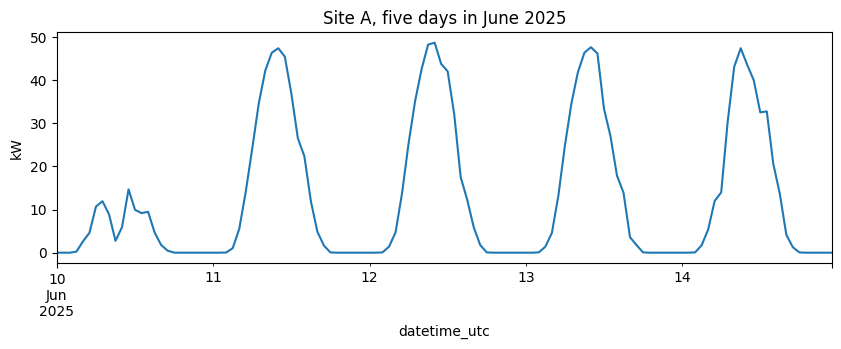

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

from solarcast import config, data

df_a = data.load_site("A")
print(pd.Series(data.data_quality_report(df_a)).to_string())
df_a.loc["2025-06-10":"2025-06-14", config.TARGET_COL].plot(figsize=(10, 3), ylabel="kW",
                                                            title="Site A, five days in June 2025");

## 2. The task, and the rule that keeps it honest
At the end of hour *t* we predict the power of hour *t+1*. The model may only use what is known at that moment:
power and weather up to hour *t*, plus the sun's position for hour *t+1* (astronomy, known in advance). It never
sees the future. An automated test changes every value from hour *t+1* onward and checks that no input changes.

We split **by time**, never at random: train on 2025, choose settings on Jan-Feb 2026, and report on
**Mar-Jun 2026**, which the model never saw.

In [ ]:
from solarcast.features import FEATURE_GROUPS

for group, cols in FEATURE_GROUPS.items():
    print(f"{group:10s}", ", ".join(cols))

power      power_lag1, power_lag2, power_lag3, power_lag6, power_roll3_mean, power_roll6_mean, power_same_hour_yesterday
weather    temp_c, humidity_pct, cloud_cover_pct, wind_speed_kmh, precip_mm, ghi_wm2, dni_wm2, dhi_wm2, cloud_cover_diff1, ghi_diff1
time_solar target_hour_sin, target_hour_cos, target_doy_sin, target_doy_cos, target_solar_elevation, target_solar_azimuth, issue_solar_elevation


## 3. Baselines and models
- **Persistence:** next hour = this hour. Simple, and hard to beat.
- **Previous-day same hour:** next hour = the same hour yesterday.
- **Model A:** gradient-boosted trees (scikit-learn) on power history and the sun's position.
- **Model B:** Model A plus the weather (cloud cover, sunlight, temperature, wind, rain).

Scores are for daytime hours (sun more than 5° above the horizon). MAE is the average error in kW; nMAE is the
same error as a percentage of the 50 kW capacity.

In [ ]:
from solarcast.pipeline import run_experiment

res_a = run_experiment("A")
res_b = run_experiment("B")
for name, res in [("Site A", res_a), ("Site B", res_b)]:
    print(f"{name}, test period Mar-Jun 2026 (never seen in training)")
    display(res.metrics["test"].round(2))

Site A, test period Mar-Jun 2026 (never seen in training)


,mae_kw,rmse_kw,nmae_pct,n
Model B,3.36,5.41,6.71,1529
Model A,3.61,5.78,7.21,1529
Previous-day same hour,7.23,11.75,14.46,1529
Persistence,7.27,9.02,14.53,1529


Site B, test period Mar-Jun 2026 (never seen in training)


,mae_kw,rmse_kw,nmae_pct,n
Model B,3.69,5.59,7.37,1093
Model A,4.11,6.06,8.23,1093
Persistence,7.13,8.88,14.26,1093
Previous-day same hour,7.65,11.84,15.30,1093


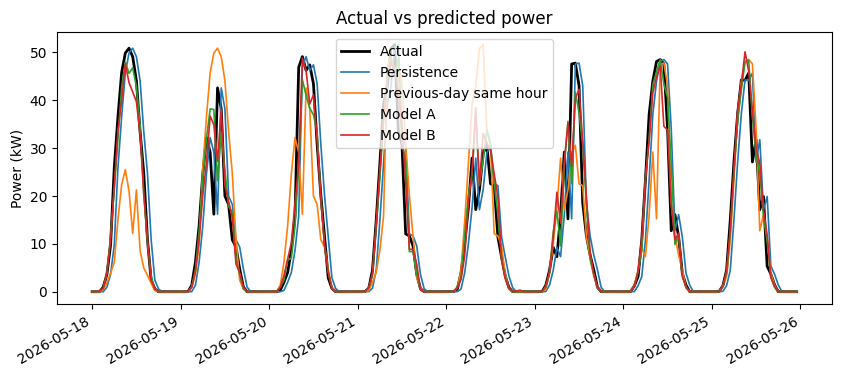

In [ ]:
from solarcast import evaluate

fig = evaluate.plot_actual_vs_predicted(res_a.splits["test"], res_a.predictions["test"],
                                        start="2026-05-18", end="2026-05-25")
fig

## 4. Where does it fail?
Errors are largest on partly cloudy and overcast hours, when clouds move in or clear within the hour. The worst
single hours are below: a forecast made at the end of one hour cannot know that a cloud is about to arrive.

In [ ]:
by_sky = evaluate.grouped_metrics(res_a.splits["test"], res_a.predictions["test"], by="sky")
display(by_sky.pivot(index="group", columns="model", values="mae_kw").round(2))
display(evaluate.worst_errors(res_a.splits["test"], res_a.predictions["test"], "Model B", k=5).round(1))

model,Model A,Model B,Persistence,Previous-day same hour
group,,,,
clear,2.81,2.37,7.66,4.89
overcast,4.39,4.14,6.80,9.70
partly_cloudy,3.93,4.02,7.21,7.95


,actual_kw,predicted_kw,cloud_cover_pct,abs_error_kw
target_time,,,,
2026-05-16 10:00:00+00:00,13.3,43.7,100.0,30.4
2026-03-17 11:00:00+00:00,14.0,42.8,91.0,28.8
2026-03-22 09:00:00+00:00,46.3,17.7,100.0,28.6
2026-04-04 10:00:00+00:00,16.4,42.0,41.0,25.6
2026-04-09 09:00:00+00:00,17.4,42.5,78.0,25.1


## 5. Our addition: from a forecast to a decision
The brief asks what decision a forecast supports. Ours: **when should the workshop charge its EV?**

Assumptions (synthetic, ours): the EV needs 40 kWh a day, an 11 kW charger, plugged in 08:00-18:00, workshop load
6 kW, grid price EUR 0.25/kWh, 0.26 kg CO2/kWh. Each hour one fixed rule decides:
`charge = max(what must be charged now to finish on time, forecast - workshop load)`, up to 11 kW.
The cost is then judged with the **actual** solar power. Only the forecast changes between strategies;
*Perfect forecast* (the real future) is the upper bound. Nothing was tuned on the test period.

In [ ]:
from solarcast import charging

COLS = ["days", "ev_grid_kwh", "solar_share_pct", "grid_kwh_saved", "money_saved_eur", "co2_saved_kg", "pct_of_perfect"]
for name, res in [("Site A", res_a), ("Site B", res_b)]:
    preds = {k: v for k, v in res.predictions["test"].items() if k != "Previous-day same hour"}
    _, summary = charging.simulate(res.splits["test"], preds)
    print(f"{name}: EV charging over the test period")
    display(summary[COLS])

Site A: EV charging over the test period


,days,ev_grid_kwh,solar_share_pct,grid_kwh_saved,money_saved_eur,co2_saved_kg,pct_of_perfect
strategy,,,,,,,
Perfect forecast,118,95.0,98.0,847.5,211.9,220.4,100.0
Persistence,118,179.8,96.2,762.6,190.7,198.3,90.0
Model B,118,304.3,93.6,638.2,159.6,165.9,75.3
Model A,118,309.5,93.4,632.9,158.2,164.6,74.7
Charge on arrival,118,942.5,80.0,0.0,0.0,0.0,0.0


Site B: EV charging over the test period


,days,ev_grid_kwh,solar_share_pct,grid_kwh_saved,money_saved_eur,co2_saved_kg,pct_of_perfect
strategy,,,,,,,
Perfect forecast,89,120.2,96.6,780.4,195.1,202.9,100.0
Persistence,89,205.6,94.2,695.0,173.7,180.7,89.1
Model B,89,252.3,92.9,648.3,162.1,168.6,83.1
Model A,89,264.9,92.6,635.7,158.9,165.3,81.5
Charge on arrival,89,900.6,74.7,0.0,0.0,0.0,0.0


**What we found.**
1. Planning with *any* forecast cuts the grid electricity the EV uses by roughly 70-80% compared with charging on
   arrival.
2. **Surprise:** in spring and summer the simple persistence forecast makes *better* charging decisions than our
   model, although our model's forecasts are about twice as accurate. The table below shows why. Persistence lags
   behind the sunrise, so it under-forecasts mornings and waits, and in summer waiting is free because plenty of
   sun follows. Our model is unbiased, so on borderline morning hours it over-forecasts about half the time and the
   EV draws grid power.
3. We tried a safety margin, chosen on the winter validation months only. There the best margin was zero
   (in winter waiting is costly), so it could not fix summer.

**Lesson:** a more accurate forecast is not automatically a more useful one. The rule also needs to know how much
sun is still coming later today, so our next step is a forecast for the rest of the day.

In [ ]:
slots = charging.daily_slots(res_a.splits["test"])
bias = pd.DataFrame({name: res_a.predictions["test"][name].reindex(slots.index) - slots["actual_kw"]
                     for name in ("Persistence", "Model B")})
bias["local hour"] = slots["hour"]
print("Site A test period: average forecast bias (forecast - actual, kW) by hour")
display(bias.groupby("local hour").mean().round(1))

Site A test period: average forecast bias (forecast - actual, kW) by hour


,Persistence,Model B
local hour,,
8,-8.1,-0.1
9,-10.5,-0.0
10,-9.3,-0.4
11,-6.1,-0.5
12,-1.7,0.8
13,0.6,0.5
14,3.2,-0.2
15,5.0,-0.5
16,6.9,-0.0


## 6. Does it work on a different solar system?
Site A's models, trained only on Site A, scored on Site B's test period without retraining. Both sites are in
the same climate region, so this is not evidence for other climates.

In [ ]:
from solarcast.pipeline import cross_site

display(cross_site(res_a, res_b).round(2))

,mae_kw,rmse_kw,nmae_pct,n
Model B,3.41,5.39,6.81,1093
Model A,3.88,5.90,7.76,1093
Persistence,7.13,8.88,14.26,1093
Previous-day same hour,7.65,11.84,15.30,1093


## 7. Interactive dashboard (optional)
Pick a site and an hour from the test period to see the forecast, the baselines and what actually happened.

In [ ]:
# @title Optional: open the interactive dashboard
RUN_DASHBOARD = False  # @param {type:"boolean"}
# Tick the box (or set True) and run this cell. It starts the Gradio dashboard and publishes it through a free
# Cloudflare quick tunnel (https://....trycloudflare.com). The link works while this Colab runtime is running.
# If the tunnel fails, it falls back to Gradio's own share link.
if RUN_DASHBOARD:
    import importlib.util, os, re, subprocess, sys, time, urllib.request
    if importlib.util.find_spec("gradio") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
    from solarcast.demo import build_demo

    app = build_demo({"A": res_a, "B": res_b})
    app.launch(server_name="127.0.0.1", server_port=7860, prevent_thread_lock=True, share=False)
    url = None
    try:
        if not os.path.exists("cloudflared"):
            urllib.request.urlretrieve(
                "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64",
                "cloudflared")
            os.chmod("cloudflared", 0o755)
        tunnel = subprocess.Popen(["./cloudflared", "tunnel", "--no-autoupdate", "--url", "http://127.0.0.1:7860"],
                                  stdout=subprocess.DEVNULL, stderr=subprocess.PIPE, text=True)
        deadline = time.time() + 60
        while url is None and time.time() < deadline:
            line = tunnel.stderr.readline()
            match = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", line)
            url = match.group(0) if match else None
    except Exception as exc:
        print("Cloudflare tunnel failed:", exc)
    if url:
        print("Dashboard (public link, valid while this runtime runs):", url)
    else:
        app.close()
        build_demo({"A": res_a, "B": res_b}).launch(share=True)
else:
    print("Dashboard is off. Tick RUN_DASHBOARD above and run this cell to open it.")

Dashboard is off. Tick RUN_DASHBOARD above and run this cell to open it.


## Limitations
- **Historical replay.** We replay past hours; this is not a live service.
- **Weather inputs are reanalysis** (what the weather was), not live forecasts. We tested archived weather
  forecasts as inputs on the validation months and they did not help.
- **One climate region** (two plants in Romania, about 18 months of data).
- **The workshop and EV are synthetic assumptions**, and the charging rule is simple.

## Credits
- Dataset: *Two-Site Solar PV Inverter & Weather Dataset (Romania)*,
  https://github.com/upb-nlp/PV-Generation-Dataset, CC BY 4.0 (includes Open-Meteo weather; solar position by pvlib).
- Libraries: scikit-learn, pandas, NumPy, Matplotlib, Gradio. Dashboard tunnel: Cloudflare `cloudflared`.
- AI tools: Claude Code helped write code, run experiments on Colab and draft documentation. The team reviewed
  everything and can explain every part.
- Full source, tests and experiments: https://github.com/nashwu0117/SolarCast-Lite (all rights reserved; see LICENSE).